In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv("../data/processed/cleaned_data.csv")

print("Dataset shape:", df.shape)

Dataset shape: (50000, 30)


In [3]:
df.columns.tolist()

['Customer_ID',
 'Age',
 'Gender',
 'Annual_Income',
 'Occupation',
 'Card_Type',
 'Credit_Limit',
 'Card_Age_Months',
 'Monthly_Spending',
 'Monthly_Transactions',
 'Avg_Transaction_Value',
 'Online_Shopping_Spending',
 'Grocery_Spending',
 'Fuel_Spending',
 'Dining_Spending',
 'Travel_Spending',
 'Entertainment_Spending',
 'Utility_Bill_Spending',
 'Outstanding_Balance',
 'Statement_Balance',
 'Payment_Amount',
 'Payment_Ratio',
 'Credit_Utilization',
 'Cash_Advance_Amount',
 'EMI_Count',
 'International_Transactions',
 'Reward_Points_Earned',
 'Reward_Points_Redeemed',
 'Mobile_App_Login',
 'Credit_Score']

In [4]:
target_column = "Credit_Score"
id_column = "Customer_ID"

print("Target:", target_column)
print("Identifier:", id_column)

Target: Credit_Score
Identifier: Customer_ID


In [5]:
feature_columns = [
    col for col in df.columns
    if col not in [target_column, id_column]
]

print("Number of predictive features:", len(feature_columns))
print(feature_columns)

Number of predictive features: 28
['Age', 'Gender', 'Annual_Income', 'Occupation', 'Card_Type', 'Credit_Limit', 'Card_Age_Months', 'Monthly_Spending', 'Monthly_Transactions', 'Avg_Transaction_Value', 'Online_Shopping_Spending', 'Grocery_Spending', 'Fuel_Spending', 'Dining_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Utility_Bill_Spending', 'Outstanding_Balance', 'Statement_Balance', 'Payment_Amount', 'Payment_Ratio', 'Credit_Utilization', 'Cash_Advance_Amount', 'EMI_Count', 'International_Transactions', 'Reward_Points_Earned', 'Reward_Points_Redeemed', 'Mobile_App_Login']


In [8]:
# Check the current dataframe columns

print("DataFrame shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

DataFrame shape: (50000, 30)

Columns:
['Customer_ID', 'Age', 'Gender', 'Annual_Income', 'Occupation', 'Card_Type', 'Credit_Limit', 'Card_Age_Months', 'Monthly_Spending', 'Monthly_Transactions', 'Avg_Transaction_Value', 'Online_Shopping_Spending', 'Grocery_Spending', 'Fuel_Spending', 'Dining_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Utility_Bill_Spending', 'Outstanding_Balance', 'Statement_Balance', 'Payment_Amount', 'Payment_Ratio', 'Credit_Utilization', 'Cash_Advance_Amount', 'EMI_Count', 'International_Transactions', 'Reward_Points_Earned', 'Reward_Points_Redeemed', 'Mobile_App_Login', 'Credit_Score']


In [7]:
# Check whether the calculated feature columns exist

calculated_features = [
    "calculated_monthly_spending",
    "spending_difference",
    "calculated_utilization",
    "spending_relative_difference"
]

for col in calculated_features:
    print(f"{col}: {col in df.columns}")

calculated_monthly_spending: False
spending_difference: False
calculated_utilization: False
spending_relative_difference: False


In [9]:
# Create calculated / derived features

df["calculated_monthly_spending"] = df["Annual_Income"] / 12

df["spending_difference"] = (
    df["Monthly_Spending"] - df["calculated_monthly_spending"]
)

df["calculated_utilization"] = (
    df["Monthly_Spending"] / df["Credit_Limit"]
)

df["spending_relative_difference"] = (
    df["spending_difference"] /
    df["calculated_monthly_spending"]
)

print("Calculated features created successfully.")

Calculated features created successfully.


In [10]:
calculated_features = [
    "calculated_monthly_spending",
    "spending_difference",
    "calculated_utilization",
    "spending_relative_difference"
]

print("Calculated features:")
print(df[calculated_features].head())

Calculated features:
   calculated_monthly_spending  spending_difference  calculated_utilization  \
0                 65617.166667        -28883.676667                0.166970   
1                 49840.333333        -19627.553333                0.269757   
2                142561.416667        -26665.706667                0.124888   
3                 59388.666667        -37584.406667                0.103338   
4                125388.500000        -34349.170000                0.159160   

   spending_relative_difference  
0                     -0.440185  
1                     -0.393809  
2                     -0.187047  
3                     -0.632855  
4                     -0.273942  


In [11]:
df[calculated_features].describe().T

,count,mean,std,min,25%,50%,75%,max
calculated_monthly_spending,50000.0,123276.492803,117271.456649,8337.500000,54814.520833,93969.125000,138635.333333,666319.250000
spending_difference,50000.0,-49404.691424,46598.355570,-447984.516667,-59820.126667,-37385.503333,-21888.808333,69610.210000
calculated_utilization,50000.0,0.144345,0.062729,0.031236,0.098505,0.130332,0.174737,0.394602
spending_relative_difference,50000.0,-0.441654,0.152286,-0.786065,-0.560474,-0.443104,-0.330018,0.135272


In [12]:
print("Missing values:")
print(df[calculated_features].isnull().sum())

print("\nInfinite values:")
print(np.isinf(df[calculated_features]).sum())

Missing values:
calculated_monthly_spending     0
spending_difference             0
calculated_utilization          0
spending_relative_difference    0
dtype: int64

Infinite values:
calculated_monthly_spending     0
spending_difference             0
calculated_utilization          0
spending_relative_difference    0
dtype: int64


In [13]:
df[calculated_features].describe()

,calculated_monthly_spending,spending_difference,calculated_utilization,spending_relative_difference
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,123276.492803,-49404.691424,0.144345,-0.441654
std,117271.456649,46598.355570,0.062729,0.152286
min,8337.500000,-447984.516667,0.031236,-0.786065
25%,54814.520833,-59820.126667,0.098505,-0.560474
50%,93969.125000,-37385.503333,0.130332,-0.443104
75%,138635.333333,-21888.808333,0.174737,-0.330018
max,666319.250000,69610.210000,0.394602,0.135272


In [14]:
# Update predictive feature list with engineered features

feature_columns = [
    col for col in df.columns
    if col not in [target_column, id_column]
]

print("Number of predictive features:", len(feature_columns))
print("\nPredictive features:")
print(feature_columns)

Number of predictive features: 32

Predictive features:
['Age', 'Gender', 'Annual_Income', 'Occupation', 'Card_Type', 'Credit_Limit', 'Card_Age_Months', 'Monthly_Spending', 'Monthly_Transactions', 'Avg_Transaction_Value', 'Online_Shopping_Spending', 'Grocery_Spending', 'Fuel_Spending', 'Dining_Spending', 'Travel_Spending', 'Entertainment_Spending', 'Utility_Bill_Spending', 'Outstanding_Balance', 'Statement_Balance', 'Payment_Amount', 'Payment_Ratio', 'Credit_Utilization', 'Cash_Advance_Amount', 'EMI_Count', 'International_Transactions', 'Reward_Points_Earned', 'Reward_Points_Redeemed', 'Mobile_App_Login', 'calculated_monthly_spending', 'spending_difference', 'calculated_utilization', 'spending_relative_difference']


In [15]:
# Correlation of engineered features with the target

engineered_correlations = (
    df[calculated_features + [target_column]]
    .corr()[target_column]
    .drop(target_column)
    .sort_values(ascending=False)
)

print("Correlation with Credit Score:")
print(engineered_correlations)

Correlation with Credit Score:
calculated_monthly_spending     0.032349
spending_relative_difference    0.013653
calculated_utilization         -0.014308
spending_difference            -0.021295
Name: Credit_Score, dtype: float64


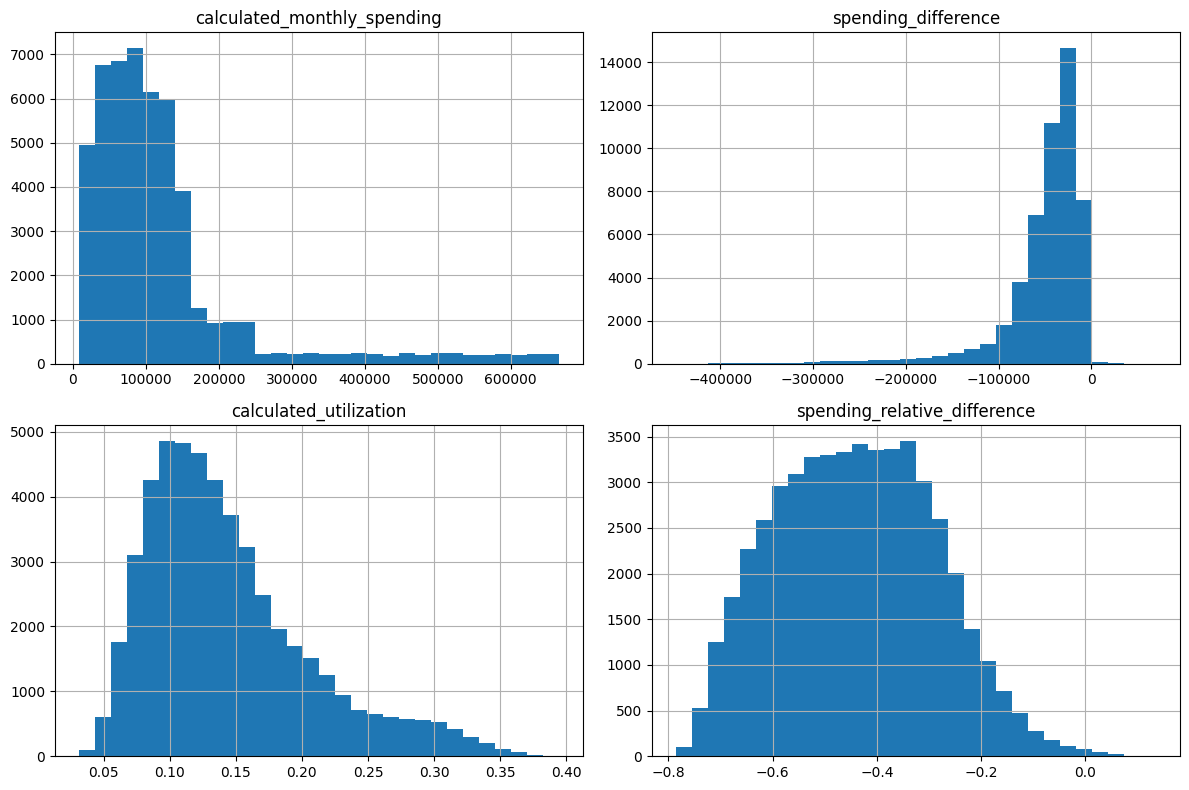

In [16]:
import matplotlib.pyplot as plt

df[calculated_features].hist(
    figsize=(12, 8),
    bins=30
)

plt.tight_layout()
plt.show()

In [17]:
output_path = "../data/processed/feature_engineered_data.csv"

df.to_csv(output_path, index=False)

print(f"Feature-engineered dataset saved to: {output_path}")
print("Final shape:", df.shape)

Feature-engineered dataset saved to: ../data/processed/feature_engineered_data.csv
Final shape: (50000, 34)
